In [1]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.insert(0, '.')
from utils import get_runs_data, show_config_differences

sns.set_style(style="darkgrid")
os.makedirs("hybrid-frozen-sweep", exist_ok=True)

In [2]:
data = get_runs_data(
    tag="plot-frozen-sweep",
    metrics=["train/exact_match_wikitext", "train/exact_match_synthetic"],
    project="llm-memorization",
)
show_config_differences(data)

Found 6 runs with tag 'plot-frozen-sweep'


,cfg.dataset.token_subset_size,cfg.model.freeze_embeddings_from_gpt2
_run_id,,
0kbf0yy9,10,True
2hd0jjfx,100,True
4u8oidmf,10000,True
fwo6239j,100,False
hxu5beuj,10,False
ule710hs,10000,False


In [3]:
TOKEN_SUBSET_COL = "cfg.dataset.token_subset_size"
FREEZE_COL       = "cfg.model.freeze_embeddings_from_gpt2"
STEP_COL         = "train/global_step"

# Color = dataset type;  linestyle = freeze condition
COLORS     = {"wikitext": "tab:blue",   "synthetic": "tab:orange"}
LINESTYLES = {True: "-",                False: "--"}
LABELS     = {
    ("wikitext",   True):  "WikiText (frozen)",
    ("wikitext",   False): "WikiText (unfrozen)",
    ("synthetic",  True):  "Synthetic (frozen)",
    ("synthetic",  False): "Synthetic (unfrozen)",
}

## Plot 1 — token_subset_size = 10

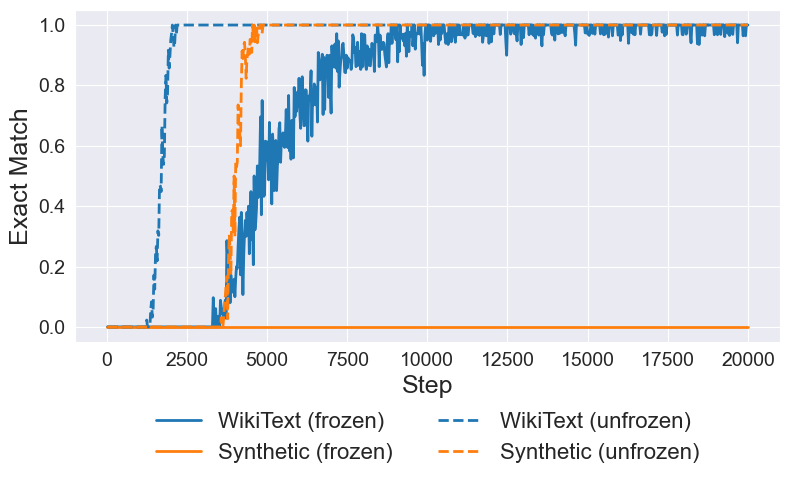

In [4]:
i = 1
token_size = 10
subset = data[data[TOKEN_SUBSET_COL] == token_size]

plt.figure(figsize=(8, 5))
for frozen in [True, False]:
    for metric_key, metric_col in [("wikitext",  "train/exact_match_wikitext"),
                                    ("synthetic", "train/exact_match_synthetic")]:
        run_data = subset[subset[FREEZE_COL] == frozen]
        steps  = run_data[STEP_COL].tolist()
        values = run_data[metric_col].tolist()
        plt.plot(steps, values,
                 label=LABELS[(metric_key, frozen)],
                 color=COLORS[metric_key],
                 linestyle=LINESTYLES[frozen],
                 linewidth=2)

plt.xlabel("Step", fontsize=18)
plt.ylabel("Exact Match", fontsize=18)
plt.xticks(fontsize=14);  plt.yticks(fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
           fontsize=16, ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(f"hybrid-frozen-sweep/plot-{i}.pdf")
plt.show()

## Plot 2 — token_subset_size = 100

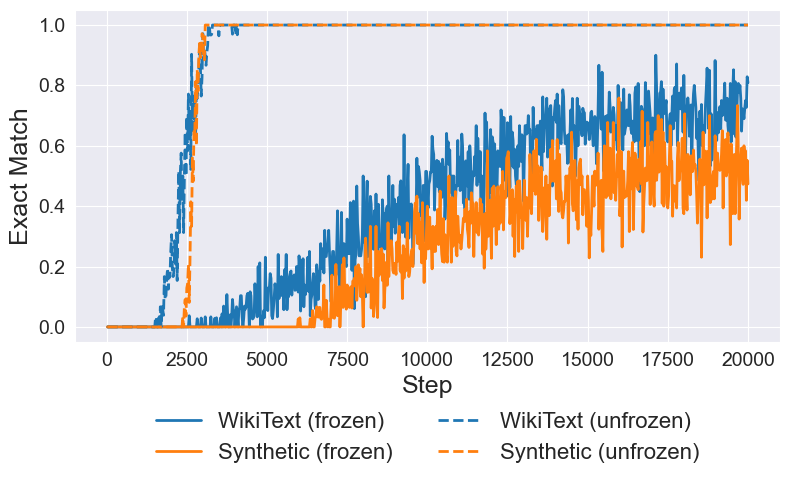

In [5]:
i = 2
token_size = 100
subset = data[data[TOKEN_SUBSET_COL] == token_size]

plt.figure(figsize=(8, 5))
for frozen in [True, False]:
    for metric_key, metric_col in [("wikitext",  "train/exact_match_wikitext"),
                                    ("synthetic", "train/exact_match_synthetic")]:
        run_data = subset[subset[FREEZE_COL] == frozen]
        steps  = run_data[STEP_COL].tolist()
        values = run_data[metric_col].tolist()
        plt.plot(steps, values,
                 label=LABELS[(metric_key, frozen)],
                 color=COLORS[metric_key],
                 linestyle=LINESTYLES[frozen],
                 linewidth=2)

plt.xlabel("Step", fontsize=18)
plt.ylabel("Exact Match", fontsize=18)
plt.xticks(fontsize=14);  plt.yticks(fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
           fontsize=16, ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(f"hybrid-frozen-sweep/plot-{i}.pdf")
plt.show()

## Plot 3 — token_subset_size = 10,000

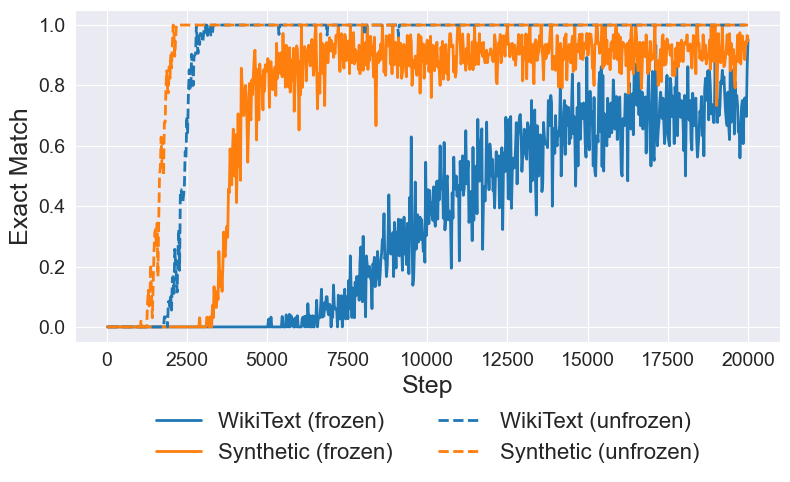

In [6]:
i = 3
token_size = 10000
subset = data[data[TOKEN_SUBSET_COL] == token_size]

plt.figure(figsize=(8, 5))
for frozen in [True, False]:
    for metric_key, metric_col in [("wikitext",  "train/exact_match_wikitext"),
                                    ("synthetic", "train/exact_match_synthetic")]:
        run_data = subset[subset[FREEZE_COL] == frozen]
        steps  = run_data[STEP_COL].tolist()
        values = run_data[metric_col].tolist()
        plt.plot(steps, values,
                 label=LABELS[(metric_key, frozen)],
                 color=COLORS[metric_key],
                 linestyle=LINESTYLES[frozen],
                 linewidth=2)

plt.xlabel("Step", fontsize=18)
plt.ylabel("Exact Match", fontsize=18)
plt.xticks(fontsize=14);  plt.yticks(fontsize=14)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15),
           fontsize=16, ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(f"hybrid-frozen-sweep/plot-{i}.pdf")
plt.show()